# Packges & Libs

In [306]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pylab as pl

In [307]:
import warnings
warnings.filterwarnings('ignore')

## Reading & Exploring Data

In [206]:
df = pd.read_csv("1632300362534233.csv")

df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


In [207]:
df.describe()

,Room,Price,Price(USD)
count,3479.000000,3.479000e+03,3.479000e+03
mean,2.079908,5.359023e+09,1.786341e+05
std,0.758275,8.099935e+09,2.699978e+05
min,0.000000,3.600000e+06,1.200000e+02
25%,2.000000,1.418250e+09,4.727500e+04
50%,2.000000,2.900000e+09,9.666667e+04
75%,2.000000,6.000000e+09,2.000000e+05
max,5.000000,9.240000e+10,3.080000e+06


## Selecting Data

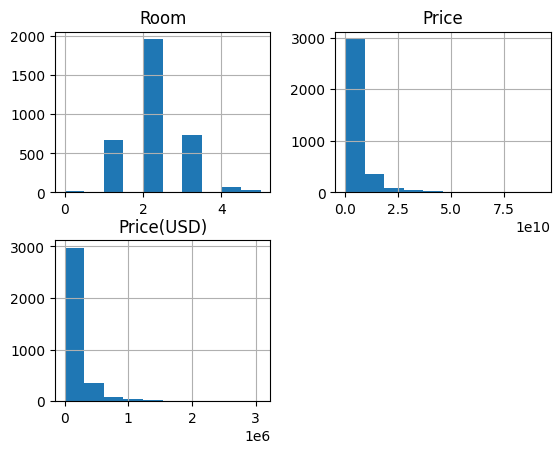

In [208]:
df.hist()
plt.show()

Area & Price(USD) Scatter Plot

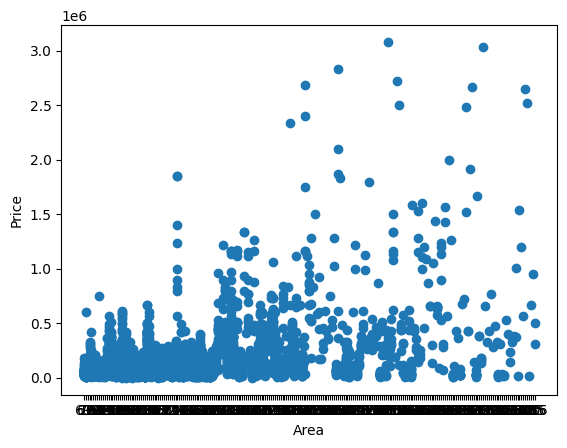

In [243]:
_df = df[["Area", "Room", "Price", "Price(USD)"]]
plt.scatter(_df.Area, _df["Price(USD)"])
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

Room & Price(USD)

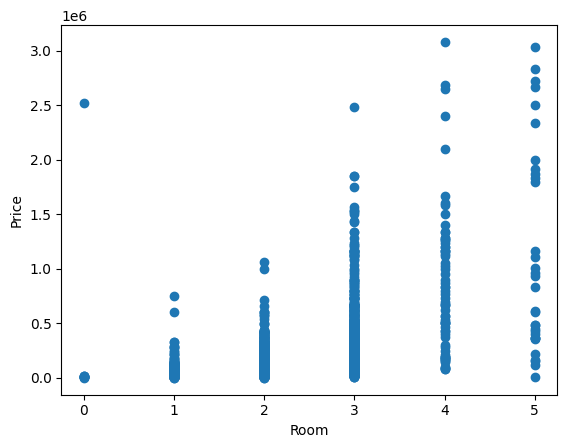

In [224]:
_df = df[["Area", "Room", "Price(USD)"]]
plt.scatter(_df.Room, _df["Price(USD)"])
plt.xlabel("Room")
plt.ylabel("Price")
plt.show()

We know other datasets aren't linear so in conclusion, we can fit a regression in Area dataset.

### Deleting Wrong Values from Area Dataset

In [263]:
df = df[df["Area"].str.isnumeric()]

## Creating Train & Test

In [252]:
df_ = df[["Area", "Room", "Price(USD)"]]
msk = np.random.rand(len(df)) < 0.8
train = df_[msk]
test = df_[~msk]

## Training by Polynomial Regression

We try to use ploynomial model to see does it fit to our dataset or not.

In [246]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn import linear_model
train_x = np.asanyarray(train[["Area"]])
train_y = np.asanyarray(train[["Price(USD)"]])

test_x = np.asanyarray(test[["Area"]])
test_y = np.asanyarray(test[["Price(USD)"]])

poly = PolynomialFeatures(degree=3)
train_x_poly = poly.fit_transform(train_x)
train_x_poly

array([[1.000000e+00, 6.300000e+01, 3.969000e+03, 2.500470e+05],
       [1.000000e+00, 9.500000e+01, 9.025000e+03, 8.573750e+05],
       [1.000000e+00, 1.230000e+02, 1.512900e+04, 1.860867e+06],
       ...,
       [1.000000e+00, 7.500000e+01, 5.625000e+03, 4.218750e+05],
       [1.000000e+00, 1.050000e+02, 1.102500e+04, 1.157625e+06],
       [1.000000e+00, 8.200000e+01, 6.724000e+03, 5.513680e+05]])

In [247]:
clf = linear_model.LinearRegression()
train_y_ = clf.fit(train_x_poly, train_y)

print("Coefficients: ", clf.coef_)
print("Intercept: ", clf.intercept_)

Coefficients:  [[ 0.00000000e+00  3.14132116e+03  1.76401707e+00 -4.35133641e-03]]
Intercept:  [-168436.74257369]


Text(0, 0.5, 'Price(USD)')

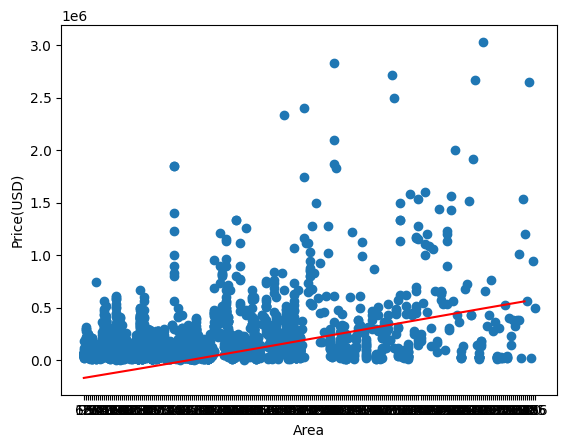

In [248]:
plt.scatter(train.Area, train["Price(USD)"])
x_ = np.arange(0.0, 220.0, 0.1)
y_ = clf.intercept_[0] + clf.coef_[0][1]*x_ + clf.coef_[0][2]*np.power(x_, 2) + clf.coef_[0][3]*np.power(x_, 3)
plt.plot(x_, y_, '-r' )
plt.xlabel("Area")
plt.ylabel("Price(USD)")

### Poly Evaluation

In [305]:
from sklearn.metrics import r2_score

test_x_poly = poly.fit_transform(test_x)
test_y_ = clf.predict(test_x_poly)

print("MAE: %.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("MSE: %.2f" % np.mean((test_y_ - test_y) ** 2))
print("R2-score: %.2f" % r2_score(test_y, test_y_))

MAE: 89230.88
MSE: 33370791589.97
R2-score: 0.64


## Training by Multiple Regression

In this time we try to use Multiple Model to see if we trian model with Area & Room Datasets. can we get a better prediction?

In [295]:
reg = linear_model.LinearRegression()
x = train[["Area", "Room"]]
y = train["Price(USD)"]

reg.fit(x, y)
print("Coefficients: ", reg.coef_)
print("Intercept: ", reg.intercept_)

Coefficients:  [ 2475.15707895 48104.77832738]
Intercept:  -185294.3471581003


### Multiple Evaluation

In [308]:
x = np.asanyarray(test[["Area", "Room"]])
y = np.asanyarray(test[["Price(USD)"]])
y_hat= reg.predict(x)

print("MSE: %.2f" % np.mean((y_hat - y) ** 2))
print("R2-score: %.2f" % r2_score(y, y_hat))

MSE: 102472971579.97
R2-score: 0.50


As we see this model has a lower R2 Score 